# Robot Kinematics and Motion Control Exercises

**Course:** Control and Planning (CAPN), Semester 6, Plaksha University

Short exercises from the course: DH-parameter forward kinematics, the unicycle and differential-drive models, and a proportional go-to-goal controller extended to waypoint tracking. The unicycle and differential-drive cells reproduce Simulink models built in class.

## 1. Forward kinematics with DH parameters (2-link planar arm, L1 = L2 = 1)

In [1]:
import numpy as np

# Function to create DH transformation matrix
def dh_transform(theta, d, a, alpha):
    """
    theta : joint angle (radians)
    d     : link offset
    a     : link length
    alpha : link twist (radians)
    """

    T = np.array([
        [np.cos(theta), -np.sin(theta)*np.cos(alpha),  np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
        [np.sin(theta),  np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
        [0,              np.sin(alpha),               np.cos(alpha),                d],
        [0,              0,                           0,                            1]
    ])

    return T


# Forward kinematics function
def forward_kinematics(dh_params):
    """
    dh_params: list of DH parameters
               each element = [theta, d, a, alpha]
    returns: final transformation matrix
    """

    T_total = np.eye(4)

    for params in dh_params:
        theta, d, a, alpha = params
        T = dh_transform(theta, d, a, alpha)
        T_total = T_total @ T

    return T_total


# Example: 2-link planar robot
L1 = 1.0
L2 = 1.0

theta1 = np.deg2rad(30)
theta2 = np.deg2rad(45)

dh_params = [
    [theta1, 0, L1, 0],
    [theta2, 0, L2, 0]
]

T = forward_kinematics(dh_params)

print("Transformation Matrix:")
print(T)

print("\nEnd Effector Position:")
print("x =", T[0,3])
print("y =", T[1,3])
print("z =", T[2,3])

Transformation Matrix:
[[ 0.25881905 -0.96592583  0.          1.12484445]
 [ 0.96592583  0.25881905  0.          1.46592583]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]

End Effector Position:
x = 1.1248444488869596
y = 1.4659258262890682
z = 0.0


## 2. Closed-form forward kinematics (L1 = 10, L2 = 7)

In [2]:
import numpy as np

# Link lengths (constant)
L1 = 10   # length of link 1
L2 = 7    # length of link 2

# Joint angles (degrees)
theta1 = 30
theta2 = 45

# Convert to radians
theta1 = np.deg2rad(theta1)
theta2 = np.deg2rad(theta2)

# Forward kinematics
x = L1*np.cos(theta1) + L2*np.cos(theta1 + theta2)
y = L1*np.sin(theta1) + L2*np.sin(theta1 + theta2)

print("End Effector Position:")
print("x =", x)
print("y =", y)

End Effector Position:
x = 10.471987353562033
y = 11.761480784023476


## 3. Unicycle model with constant v and omega (Python version of the Simulink model)

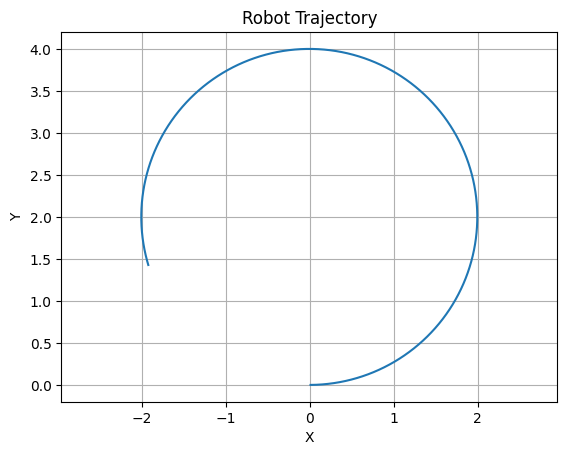

Final X: -1.921426242879613
Final Y: 1.4278780229582637
Final Theta: 4.999999999999916


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
dt = 0.01          # time step
T = 10             # total time
steps = int(T/dt)

# Inputs (same as Simulink inputs)
v = 1.0            # linear velocity (m/s)
omega = 0.5        # angular velocity (rad/s)

# Initialize variables
x = 0
y = 0
theta = 0

# Store trajectory
x_list = []
y_list = []
theta_list = []

# Simulation loop (equivalent to integrator blocks)
for i in range(steps):

    # Integrate omega → theta
    theta = theta + omega * dt

    # Compute derivatives
    x_dot = v * np.cos(theta)
    y_dot = v * np.sin(theta)

    # Integrate to get position
    x = x + x_dot * dt
    y = y + y_dot * dt

    # Store values
    x_list.append(x)
    y_list.append(y)
    theta_list.append(theta)

# Plot trajectory
plt.plot(x_list, y_list)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Robot Trajectory")
plt.axis("equal")
plt.grid()
plt.show()

# Final position
print("Final X:", x)
print("Final Y:", y)
print("Final Theta:", theta)

## 4. Differential-drive robot from wheel speeds

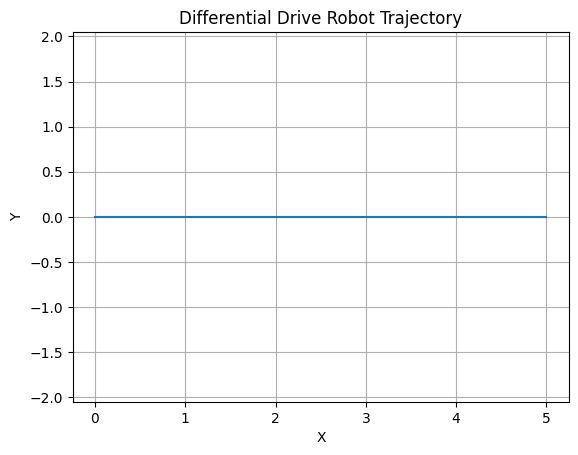

Final position:
x = 4.999999999999916
y = 0.0
theta = 0.0


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Robot parameters
R = 0.05     # wheel radius (meters)
L = 0.20     # distance between wheels (meters)

# Wheel angular velocities (rad/s)
omega_r = 10
omega_l = 10

# Simulation parameters
dt = 0.01
T = 10
steps = int(T/dt)

# Initial pose
x = 0
y = 0
theta = 0

# Store trajectory
x_list = []
y_list = []

for i in range(steps):

    # Step 1: compute robot velocities
    v = (R/2) * (omega_r + omega_l)
    omega = (R/L) * (omega_r - omega_l)

    # Step 2: integrate (same as your Simulink model)
    theta += omega * dt
    x += v * np.cos(theta) * dt
    y += v * np.sin(theta) * dt

    # Store
    x_list.append(x)
    y_list.append(y)

# Plot
plt.plot(x_list, y_list)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Differential Drive Robot Trajectory")
plt.axis("equal")
plt.grid()
plt.show()

print("Final position:")
print("x =", x)
print("y =", y)
print("theta =", theta)

## 5. Differential-drive trajectory with final heading

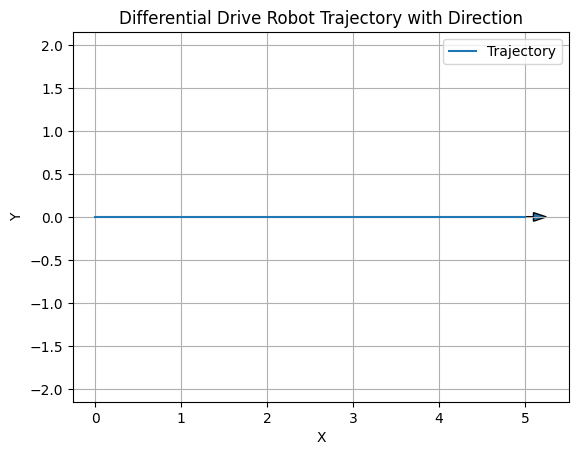

Final theta (radians): 0.0
Final theta (degrees): 0.0


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Robot parameters
R = 0.05
L = 0.20

# Wheel speeds (rad/s)
omega_r = 10
omega_l = 10

# Simulation settings
dt = 0.01
T = 10
steps = int(T/dt)

# Initial pose
x = 0
y = 0
theta = 0   # radians

# Store trajectory
x_list = []
y_list = []

for i in range(steps):

    v = (R/2)*(omega_r + omega_l)
    omega = (R/L)*(omega_r - omega_l)

    theta += omega*dt
    x += v*np.cos(theta)*dt
    y += v*np.sin(theta)*dt

    x_list.append(x)
    y_list.append(y)

# Plot trajectory
plt.figure()
plt.plot(x_list, y_list, label="Trajectory")

# Add arrow at final position showing direction
arrow_length = 0.1
plt.arrow(
    x, y,
    arrow_length*np.cos(theta),
    arrow_length*np.sin(theta),
    head_width=0.1,
    head_length=0.15,
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Differential Drive Robot Trajectory with Direction")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

print("Final theta (radians):", theta)
print("Final theta (degrees):", np.rad2deg(theta))

## 6. Go-to-goal controller (proportional on distance and heading)

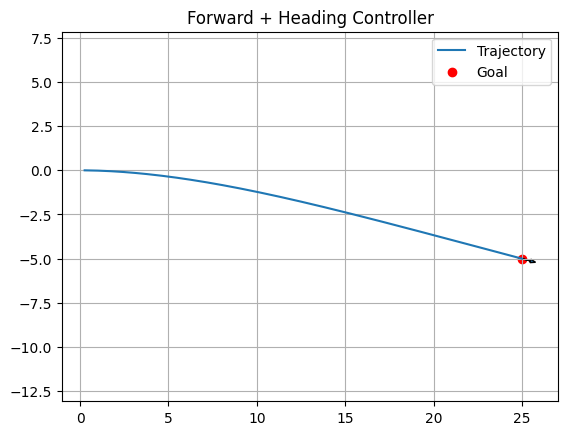

Final position: 24.998933186436613 -4.9997157638082
Final heading (deg): -14.919010131582443


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Robot parameters
R = 0.05     # wheel radius
L = 0.20     # wheel separation

# Controller gains
k_v = 1.0
k_theta = 4.0

# Goal position
x_goal = 25
y_goal = -5

# Simulation settings
dt = 0.01
T = 10
steps = int(T/dt)

# Initial pose
x = 0
y = 0
theta = 0

# Store trajectory
x_list = []
y_list = []

for i in range(steps):

    # Distance error
    dx = x_goal - x
    dy = y_goal - y
    distance = np.sqrt(dx**2 + dy**2)

    # Desired heading
    theta_goal = np.arctan2(dy, dx)

    # Heading error
    theta_error = theta_goal - theta

    # Normalize angle to [-pi, pi]
    theta_error = np.arctan2(np.sin(theta_error), np.cos(theta_error))

    # Controllers
    v = k_v * distance
    omega = k_theta * theta_error

    # Convert to wheel speeds
    omega_r = (2*v + omega*L)/(2*R)
    omega_l = (2*v - omega*L)/(2*R)

    # Forward kinematics
    v_robot = (R/2)*(omega_r + omega_l)
    omega_robot = (R/L)*(omega_r - omega_l)

    theta += omega_robot * dt
    x += v_robot * np.cos(theta) * dt
    y += v_robot * np.sin(theta) * dt

    x_list.append(x)
    y_list.append(y)

# Plot
plt.figure()
plt.plot(x_list, y_list, label="Trajectory")
plt.scatter(x_goal, y_goal, color="red", label="Goal")

# Arrow showing final heading
plt.arrow(
    x, y,
    0.5*np.cos(theta),
    0.5*np.sin(theta),
    head_width=0.2
)

plt.axis("equal")
plt.grid()
plt.legend()
plt.title("Forward + Heading Controller")
plt.show()

print("Final position:", x, y)
print("Final heading (deg):", np.rad2deg(theta))

## 7. Waypoint tracking

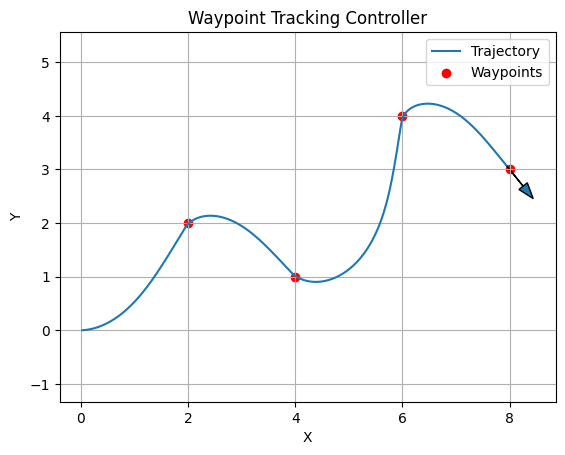

Final position: 7.937515791790237 3.077254349543321
Final waypoint index reached: 4


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Robot parameters
R = 0.05
L = 0.20

# Controller gains
k_v = 1.0
k_theta = 4.0

# Waypoints (array of x,y)
waypoints = np.array([
    [2, 2],
    [4, 1],
    [6, 4],
    [8, 3]
])

# Simulation settings
dt = 0.01
T = 30
steps = int(T/dt)

# Stop tolerance
pos_tolerance = 0.1

# Initial pose
x = 0
y = 0
theta = 0

# Waypoint index
current_wp = 0

# Store trajectory
x_list = []
y_list = []

for i in range(steps):

    # Stop if all waypoints reached
    if current_wp >= len(waypoints):
        break

    # Current goal
    x_goal, y_goal = waypoints[current_wp]

    # Errors
    dx = x_goal - x
    dy = y_goal - y

    distance = np.sqrt(dx**2 + dy**2)

    # Check if waypoint reached
    if distance < pos_tolerance:
        current_wp += 1
        continue

    # Desired heading
    theta_goal = np.arctan2(dy, dx)

    # Heading error
    theta_error = theta_goal - theta
    theta_error = np.arctan2(np.sin(theta_error), np.cos(theta_error))

    # Controllers
    v = k_v * distance
    omega = k_theta * theta_error

    # Convert to wheel speeds
    omega_r = (2*v + omega*L)/(2*R)
    omega_l = (2*v - omega*L)/(2*R)

    # Forward kinematics
    v_robot = (R/2)*(omega_r + omega_l)
    omega_robot = (R/L)*(omega_r - omega_l)

    theta += omega_robot * dt
    x += v_robot * np.cos(theta) * dt
    y += v_robot * np.sin(theta) * dt

    # Store trajectory
    x_list.append(x)
    y_list.append(y)

# Plot trajectory
plt.figure()
plt.plot(x_list, y_list, label="Trajectory")

# Plot waypoints
plt.scatter(waypoints[:,0], waypoints[:,1], color="red", label="Waypoints")

# Final heading arrow
plt.arrow(
    x, y,
    0.5*np.cos(theta),
    0.5*np.sin(theta),
    head_width=0.2
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Waypoint Tracking Controller")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

print("Final position:", x, y)
print("Final waypoint index reached:", current_wp)

## 8. Waypoint tracking: two waypoints straight ahead and to the side

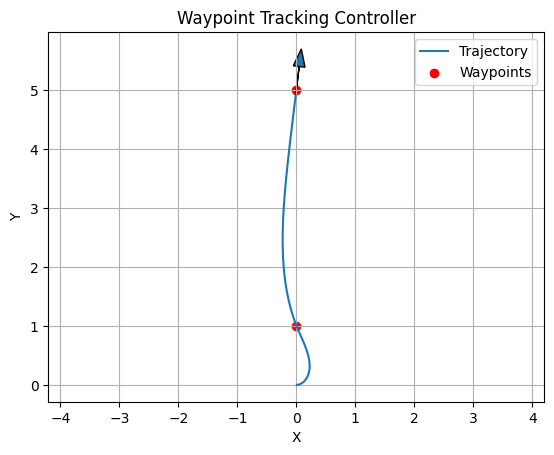

Final position: -0.012015734438078213 4.901120392406109
Final waypoint index reached: 2


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Robot parameters
R = 0.05
L = 0.20

# Controller gains
k_v = 1.0
k_theta = 4.0

# Waypoints
waypoints = np.array([
    [0,1],
    [0,5]
])

# Simulation settings
dt = 0.01
T = 30
steps = int(T/dt)

pos_tolerance = 0.1

# Initial pose
x, y, theta = 0, 0, 0
current_wp = 0

# Storage
x_list, y_list = [], []
omega_r_list, omega_l_list = [], []
delta_omega_r_list, delta_omega_l_list = [], []

# Initial wheel speeds
omega_r_prev = 0
omega_l_prev = 0

for i in range(steps):

    if current_wp >= len(waypoints):
        break

    x_goal, y_goal = waypoints[current_wp]

    dx = x_goal - x
    dy = y_goal - y
    distance = np.sqrt(dx**2 + dy**2)

    if distance < pos_tolerance:
        current_wp += 1
        continue

    theta_goal = np.arctan2(dy, dx)

    theta_error = theta_goal - theta
    theta_error = np.arctan2(np.sin(theta_error), np.cos(theta_error))

    # Controllers
    v = k_v * distance
    omega = k_theta * theta_error

    # Wheel speeds
    omega_r = (2*v + omega*L)/(2*R)
    omega_l = (2*v - omega*L)/(2*R)

    # Change in wheel speeds
    delta_omega_r = omega_r - omega_r_prev
    delta_omega_l = omega_l - omega_l_prev

    # Store
    omega_r_list.append(omega_r)
    omega_l_list.append(omega_l)
    delta_omega_r_list.append(delta_omega_r)
    delta_omega_l_list.append(delta_omega_l)

    # Update previous values
    omega_r_prev = omega_r
    omega_l_prev = omega_l

    # Forward kinematics
    v_robot = (R/2)*(omega_r + omega_l)
    omega_robot = (R/L)*(omega_r - omega_l)

    theta += omega_robot * dt
    x += v_robot * np.cos(theta) * dt
    y += v_robot * np.sin(theta) * dt

    x_list.append(x)
    y_list.append(y)

# Plot trajectory
plt.figure()
plt.plot(x_list, y_list, label="Trajectory")

# Plot waypoints
plt.scatter(waypoints[:,0], waypoints[:,1], color="red", label="Waypoints")

# Final heading arrow
plt.arrow(
    x, y,
    0.5*np.cos(theta),
    0.5*np.sin(theta),
    head_width=0.2
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Waypoint Tracking Controller")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

print("Final position:", x, y)
print("Final waypoint index reached:", current_wp)



# Convert to numpy arrays
delta_omega_r_list = np.array(delta_omega_r_list)
delta_omega_l_list = np.array(delta_omega_l_list)

# # Print first 10 values
# print("First 10 timestep changes:\n")
# for i in range(min(10, len(delta_omega_r_list))):
#     print(f"Step {i}: Δωr = {delta_omega_r_list[i]:.3f}, Δωl = {delta_omega_l_list[i]:.3f}")

# # Plot change in wheel speeds
# plt.figure()
# plt.plot(delta_omega_r_list, label="Δωr")
# plt.plot(delta_omega_l_list, label="Δωl")
# plt.title("Change in Wheel Angular Velocity per Timestep")
# plt.xlabel("Timestep")
# plt.ylabel("Angular velocity change (rad/s)")
# plt.grid()
# plt.legend()
# plt.show()